# Hermes Agent 协作篇：Gateway、Profile、Delegation 与 Kanban


## 从一个终端助手，到多个入口与多个协作者

第 03 篇讨论了技能复用、事件钩子、插件扩展和定时执行。接下来要解决的是：怎样通过消息平台使用 Agent，怎样让不同用途的助手保存各自状态，以及怎样把大任务拆给多个协作者。

| 模块 | 本章要解决的问题 |
| --- | --- |
| Gateway | Telegram、微信、邮件等消息怎样进入 Agent，再回到原平台？ |
| Profile | 代码助手、资料助手、个人助手怎样分别保存配置与记忆？ |
| Delegation | 当前任务中，怎样让子 Agent 处理独立子问题？ |
| Kanban | 工作跨会话、跨角色或需要人工介入时，怎样记录任务与交接？ |

本篇依据本地《04-协作篇.md》整理，沿用前三篇和“李勃老师零到全栈 7.2”的概念说明、分步示例、表格与复习题排版。课件以 v0.16.0 为基准；关键字段另对照了 2026-10-09 读取的官方文档与公开 main 源码。

所有单元格均为 Markdown，代码和命令只供阅读。本文没有接入消息平台、批准配对、安装服务、创建 Profile、启动子 Agent 或运行 Kanban 任务。


## 先分清：入口、身份、临时委派和持久队列

| 名称 | 描述什么 | 生命周期 |
| --- | --- | --- |
| CLI | 终端交互入口 | 可以短时运行，也可以持续对话 |
| Gateway | 消息适配、路由与后台维护进程 | 通常长期运行 |
| Profile | 一份配置与数据身份 | 跨会话、跨重启保留 |
| Agent | 使用相应配置工作的运行实例 | 当前执行过程 |
| Delegated child | 当前父任务创建的子 Agent | 通常围绕一项委派任务工作 |
| Kanban Task | 持久任务板上的工作单元 | 可经历多次运行、阻塞和审查 |

~~~text
Telegram / CLI / Dashboard → Agent 使用某个 Profile
                              ├─ delegate_task → 临时子任务
                              └─ Kanban → 持久任务、依赖与角色交接
~~~

子 Agent 有新对话，不等于获得一个长期独立 Profile。一个消息 Bot 也不等于一个单独操作系统账号；它只是平台侧入口。

先确定哪类状态需要保留，再选择协作方式，可以避免把短任务做成复杂队列，或者让跨天任务只剩在聊天摘要里。


## Gateway：把平台消息转成 Agent 会话

Gateway 连接消息平台，接收用户输入，决定消息属于哪个会话和 Profile，调用 Hermes Agent，再把回复送回相应聊天。

~~~text
平台消息 → Adapter → 身份与访问检查 → 会话路由
    → Agent / 工具循环 → 格式化与分段 → 平台回复
~~~

Gateway 与 CLI 使用同一套 Hermes 程序，以及所选 Profile 的配置、技能、记忆、工具和会话存储。入口不同，不代表每条消息天然开启一份全新配置。

| Gateway 负责 | Agent 负责 |
| --- | --- |
| 平台连接、消息接收与发送 | 理解目标、推理与选择工具 |
| 按聊天来源管理会话 | 在当前上下文中完成任务 |
| 访问名单、配对与命令入口检查 | 依据可用工具和任务约束工作 |
| Cron、Kanban 等后台维护入口 | 执行到期或被调度的具体任务 |

课件把 CLI 概括为单次交互，实际 CLI 也能持续对话。核心区别是终端入口与长期消息适配进程，而不是“CLI 只允许一轮”。


## 配置、前台运行与后台服务

先使用配置向导，再以前台模式观察连接状态：

~~~bash
hermes gateway setup
hermes gateway run
~~~

课件使用不带子命令的 hermes gateway 作为前台入口。这里采用当前解析器明确提供的 run，阅读日志时更容易辨认启动方式。

长期运行时可以使用服务入口：

~~~bash
hermes gateway install
hermes gateway start
hermes gateway status
hermes gateway stop
~~~

以上是管理入口，不是要求先启动前台进程，再同时启动一份后台进程。完成调试后，应确认所采用的长期运行方式和已存在的进程。

| 环境 | 当前常见的长期运行方式 |
| --- | --- |
| Linux | systemd 用户服务；也支持系统服务 |
| macOS | launchd 用户代理 |
| Windows 原生 | 当前版本使用 Task Scheduler 注册登录启动任务 |
| WSL / Docker | 常见为明确的前台进程，结合所在环境的进程管理 |

服务状态为“已注册”或“进程存在”，仍不证明平台凭证、网络和模型都能正常工作；连接日志与一次受控消息测试需要分别确认。


## Linux 的用户服务与系统服务，不是同一层级

课件把普通 install 称为系统服务，但其前面的说明实际区分了用户服务与系统服务。Linux 上应按作用域理解：

~~~bash
hermes gateway install
hermes gateway status
~~~

上面管理用户服务。显式使用 --system 才指向 Linux 系统作用域：

~~~bash
sudo hermes gateway install --system
hermes gateway status --system
~~~

| 作用域 | 需要关注什么 |
| --- | --- |
| 用户服务 | 用户会话、用户服务管理器，以及是否配置登出后持续运行 |
| 系统服务 | 开机启动、运行账号、安装与管理权限 |

用户服务能否在登出后继续运行，取决于系统的 linger 等配置；不要仅凭“用了 install”就断言重启后一定在线。--system 也不能直接搬到 Windows 或 macOS。

当前 Windows 文档说明计划任务负责启动器，而启动器之后 Gateway 崩溃不必然触发任务级自动重启。需要分别确认登录启动、实际进程健康和恢复机制。


## Telegram 接入：Bot 身份、Hermes 配置、用户授权

Telegram 接入可以拆成三件事：建立 Bot 身份、接通 Hermes、允许具体用户使用。

1. 在 Telegram 找到 @BotFather，按 /newbot 流程创建 Bot，获得 Bot Token。
2. 在 Hermes 所用数据目录配置 Token，并通过 gateway setup 选择 Telegram。
3. 启动 Gateway，观察平台连接日志；未知用户私信时，按配置进行配对。

BotFather 中输入的命令不是系统终端命令：

~~~text
/newbot
~~~

.env 的阅读示例使用占位值：

~~~dotenv
TELEGRAM_BOT_TOKEN=YOUR_BOT_TOKEN
~~~

~~~bash
hermes gateway setup
hermes gateway run
~~~

课件用 echo ... >> .env 写 Token。笔记中改成文件内容示例，避免把真实 Token 放进终端历史，也避免反复追加同名配置。Token 是 Bot 凭证，不是用户 ID，也不是配对码。

本文只整理流程，没有访问 BotFather、创建 Bot 或发送 Telegram 消息。


## 配对：平台账号接通之后，谁能使用 Bot？

配对解决的是用户准入。平台支持且开启私信配对时，未知用户向 Bot 发私信，会得到一枚一次性代码；管理员在本机核对请求后批准。

~~~bash
hermes pairing list
hermes pairing approve telegram PAIRING_CODE
hermes pairing revoke telegram USER_ID
~~~

PAIRING_CODE 与 USER_ID 分别替换为待处理请求的真实配对码和平台用户 ID。它们不能互换，批准或撤销也要指定正确平台和 Profile。

| 对象 | 作用 |
| --- | --- |
| Bot Token | Gateway 代表哪个平台 Bot 连接 |
| User ID | 哪个用户发来了消息 |
| Pairing code | 把某次待授权请求交给管理员确认 |
| Approved record | 记录已经配对的用户 |

课件与当前文档都说明配对码有约一小时有效期、速率限制和随机生成机制。配对只授予对应入口的使用资格，不意味着获得了所有操作系统权限。

平台行为不完全相同。当前 Email 默认忽略未知发件人，邮件配对需要显式开启，不能把“所有未知用户都会收到配对码”写成统一规律。


## 允许列表：使用平台实际返回的标识

如果用户范围固定，可以直接配置允许列表：

~~~dotenv
TELEGRAM_ALLOWED_USERS=123456789,987654321
GATEWAY_ALLOWED_USERS=123456789,987654321
~~~

数字是示例，必须替换为真实用户 ID。两个字段展示平台专属名单与通用名单，不需要为了“更保险”重复配置同一名单；具体优先级按所在版本和平台确认。

| 平台 | 常见的用户标识 |
| --- | --- |
| Telegram / Discord | 平台用户 ID，而不是显示昵称 |
| Weixin | iLink 事件中的发送者标识，不等同于 Telegram 数字 ID |
| Email | 按适配器规则识别的发件地址，仍需可信的邮件认证判断 |
| Feishu / WeCom 等 | 对应平台的开放或企业用户标识 |

课件同时展示了 GATEWAY_ALLOW_ALL_USERS=true、EMAIL_ALLOW_ALL_USERS=true 等测试配置。它们会扩大消息准入范围，不应在没有理解行为时与“受限名单”配置混用。

访问名单决定谁能到达 Agent；Bot 进入群聊、平台侧隐私模式、@ 提及规则和斜杠权限仍是其他独立条件。没有回复时，需要逐层排查。


## 斜杠命令权限：准入之后，再区分管理员与普通用户

课件的权限顺序是：先判断用户能否使用 Gateway，再判断当前私信或群聊作用域的命令权限层级。

~~~yaml
gateway:
  platforms:
    discord:
      extra:
        allow_from: ["111", "222", "333"]
        allow_admin_from: ["111"]
        user_allowed_commands: [status, model]
        group_allow_admin_from: ["111"]
        group_user_allowed_commands: [status]
~~~

ID 均为示例。私信管理员与群聊管理员分别配置，不应推断“私信是管理员，群聊也自动是管理员”。

| 状态 | 斜杠命令访问 |
| --- | --- |
| 用户未通过 Gateway 准入 | 先按平台准入策略处理 |
| 某作用域未配置 admin 列表 | 为兼容旧行为，通常不启用管理员分层 |
| 已配置 admin，且用户在其中 | 可使用相应注册命令 |
| 已配置 admin，普通已允许用户 | 只能使用显式放行的命令，以及 /help、/whoami |

会话中查看身份与可用入口：

~~~text
/whoami
/help
~~~

当前文档明确这套分层主要控制斜杠命令，普通聊天并不因此被禁用。它不能替代工具集限制、执行环境权限或审批策略；普通聊天仍可能引导 Agent 使用可用工具。


## 平台很多，但连接协议与功能范围各不相同

课件列出 23+ 平台，这是对应版本的支持清单，不是每个安装实例都已接通的数量。

| 平台类别 | 课件示例 | 配置时的重点 |
| --- | --- | --- |
| 常见即时消息 | Telegram、Discord、Slack、WhatsApp、Signal | Bot 或账号身份、用户与聊天作用域 |
| 国内平台 | Weixin、WeCom、DingTalk、Feishu、QQBot、Yuanbao | 区分个人与企业接口、实际账号能力 |
| 邮件与短信 | Email、Twilio SMS | IMAP / SMTP 或短信服务凭证与目标 |
| 企业与开放协议 | Matrix、Mattermost、Teams、Google Chat、IRC、LINE、SimpleX | 平台权限、适配器和部署方式 |
| 通知与自动化 | ntfy、Webhook、Home Assistant、BlueBubbles 等 | 入口与出口、订阅地址、服务可达性 |

同一个 Gateway 可以连接多个平台，但平台适配器可能有不同的消息长度、附件、线程和用户身份规则。群聊支持也不能仅从“已支持该平台”推出。

技能能管理邮箱，与 Gateway 能接收邮件是不同能力。例如 Himalaya Skill 依赖相应 CLI；Email Gateway 使用 IMAP / SMTP 适配消息入口，配置不能互相替代。


## Email 示例：收件、发件和可信发件人分别配置

课件给出 163 邮箱的 IMAP / SMTP 示例。下面采用占位域名展示字段，真实主机、端口和授权码应使用邮箱提供商说明。

~~~dotenv
EMAIL_ADDRESS=hermes@example.com
EMAIL_PASSWORD=YOUR_APP_PASSWORD
EMAIL_IMAP_HOST=imap.example.com
EMAIL_IMAP_PORT=993
EMAIL_SMTP_HOST=smtp.example.com
EMAIL_SMTP_PORT=465
EMAIL_ALLOWED_USERS=you@example.com
EMAIL_AUTHSERV_ID=YOUR_MAIL_SERVER_AUTHSERV_ID
~~~

| 字段 | 主要作用 |
| --- | --- |
| EMAIL_ADDRESS / PASSWORD | 邮箱身份与登录凭证；常见为应用授权码 |
| EMAIL_IMAP_HOST / PORT | 收件连接 |
| EMAIL_SMTP_HOST / PORT | 发件连接 |
| EMAIL_ALLOWED_USERS | 允许访问的发件人范围 |
| EMAIL_AUTHSERV_ID | 当前版本邮件认证判断使用的可信认证服务器标识 |

课件没列 EMAIL_AUTHSERV_ID；当前官方文档要求结合接收服务器的 Authentication-Results 认证信息配置它。不能仅看 From 字段就认定发件人真实，也不能随意填一个域名代替服务器实际认证标识。

当前文档常见 465 为隐式 TLS，587 为 STARTTLS；具体传输设置要按提供商核对。本文未写真实邮箱账号或密码，也没有读取、发送邮件。


## Weixin 示例：扫码接通 iLink Bot，使用真实发送者标识

课件的微信地址指向 Weixin 适配器。当前文档说明它使用 iLink Bot 接口，与 WeCom 企业微信不同；扫码得到的是 Bot 身份，不是可以任意操作个人微信的完整账户自动化接口。

向导入口：

~~~bash
hermes gateway setup
~~~

选择 Weixin 后，按向导扫码与确认，凭证会按版本保存到相应账户目录。配置示例：

~~~dotenv
WEIXIN_ACCOUNT_ID=YOUR_ILINK_ACCOUNT_ID
WEIXIN_DM_POLICY=allowlist
WEIXIN_ALLOWED_USERS=YOUR_WEIXIN_USER_ID
WEIXIN_GROUP_POLICY=disabled
WEIXIN_HOME_CHANNEL=YOUR_CHAT_ID
~~~

| 对象 | 含义 |
| --- | --- |
| ACCOUNT_ID | 向导接通的 iLink Bot 身份 |
| TOKEN | 该 Bot 的凭证，通常由向导保存，无需重复手写 |
| ALLOWED_USERS | 消息事件中的真实发送者 ID |
| HOME_CHANNEL | 定时结果或通知的默认目标，不是用户名 |

课件同时使用 pairing 与 ALLOW_ALL_USERS=true，容易让测试准入与配对策略混淆。本示例采用明确的 allowlist 策略，不照抄其中的真实账号路径与标识。

当前官方文档指出，许多 iLink Bot 身份无法接收普通微信群事件；即使打开 group_policy，也不能生成平台未投递的事件。接入后应先确认私信，再判断账号实际支持的群聊能力。


## Profile：给不同用途的助手分别保存状态

Profile 是一份独立 Hermes home，保存自己的配置、密钥文件、SOUL.md、会话、技能、记忆、Cron 和状态数据库。

~~~text
<默认 Hermes 数据根目录>/
├── config.yaml
├── state.db
└── profiles/
    ├── coder/
    │   ├── config.yaml
    │   ├── .env
    │   ├── SOUL.md
    │   ├── state.db
    │   ├── skills/
    │   └── memories/
    └── researcher/
        └── ...
~~~

上图是概念目录，实际文件会随初始化与使用逐步出现。Windows、WSL、Linux 和自定义 HERMES_HOME 应按各自数据根目录定位，不能统一硬编码 ~/.hermes。

| Profile | 可以保存的角色特点 |
| --- | --- |
| coder | 代码工具、仓库规则、实现与验证习惯 |
| researcher | 来源核对、研究技能、资料整理偏好 |
| assistant | 个人任务、语言偏好、消息入口 |

这些身份能跨任务积累状态。一个 Profile 不只是不同的 system prompt；但多个 Profile 通常仍运行在同一安装环境和操作系统用户权限下。


## 创建 Profile，并写清楚它能做什么

创建一个新代码助手：

~~~bash
hermes profile create coder \
  --description "阅读源码，完成已明确的代码修改，排查测试或构建问题，运行必要验证，并说明结果与剩余问题。"
hermes -p coder setup
hermes -p coder chat
~~~

空白 Profile 是新状态，通常会初始化内置技能；它不等于所有凭证和工具都已经配好。当前版本另有 --no-skills，可创建不自动播种内置技能的 Profile。

description 用于帮助 Kanban 按实际角色路由任务。比“全能高手”更有用的描述，应说明输入、职责与输出，例如“读取原始公告并给出来源链接，不直接部署服务”。

创建后补充或查看描述：

~~~bash
hermes profile list
hermes profile describe coder
hermes profile describe coder --text "负责代码实现、验证与具体问题修复。"
hermes profile describe coder --auto
~~~

--auto 会按版本使用辅助模型生成描述，可能调用模型；不是纯本地字符串整理。描述也不能让不存在的工具或凭证自动出现。


## clone 与 clone-all：复制新身份，不等于完整备份

下面展示不同克隆形式，名称应替换为未占用的目标 Profile：

~~~bash
hermes profile create coder-copy --clone
hermes profile create coder-copy-all --clone-all
hermes profile create researcher-copy --clone --clone-from researcher
~~~

| 形式 | 课件说明 | 当前文档需要补充的区别 |
| --- | --- | --- |
| 不带 clone | 新配置与状态 | 通常播种内置技能，模型与凭证需配置 |
| --clone | 复制 config、.env、SOUL.md | 当前还复制技能、部分记忆与相关插件设置；会话与 Cron 仍从空状态开始 |
| --clone-all | 克隆完整状态 | 当前排除历史、数据库、部分运行时数据及 Cron，不能当作完整备份 |
| --clone-from | 选择来源身份 | 按指定来源复制，不是自动把多个 Profile 合并 |

当前版本克隆默认不带消息 Bot Token、准入名单和相应平台状态，以免两个身份抢同一个 Bot 的长轮询连接。模型或工具 API 密钥仍可能被复制；使用新 Profile 时要检查它应使用哪份凭证。

课件用 backup --clone-all 表示完整状态克隆。当前版本真正需要保留历史与任务定义时，应核对 profile export 或 backup 的备份范围与恢复方式，而不是只看 clone-all 的名字。

外部记忆提供商的设置可能仍指向同一后端或同一 bank。目录不同，不能据此保证外部存储也完全分离。


## 指定身份、别名与默认身份

创建 Profile 后，Hermes 通常会生成同名包装命令，例如 coder。显式形式和别名形式对应同一身份：

~~~bash
hermes -p coder chat
coder chat
~~~

这两行是替代入口，不需要同时启动两个会话。别名是否能直接找到，还取决于包装脚本是否创建、所在目录是否在 PATH。

查看工具、检查环境或选择模型时，也要指定同一个 Profile：

~~~bash
hermes -p coder doctor
hermes -p coder skills list
hermes -p coder model
~~~

设置默认身份：

~~~bash
hermes profile use coder
hermes profile use default
~~~

use 是后续未显式指定身份时的默认选择，不是迁移已有会话、合并数据或让所有正在运行的进程立即切换身份。调试多 Profile 时，明确使用 -p 更容易确认命令对象。


## HERMES_HOME、工作目录和执行权限分开看

| 设置或对象 | 控制什么 | 不自动保证什么 |
| --- | --- | --- |
| HERMES_HOME / Profile | Hermes 配置与数据位置 | 工具只能访问该目录 |
| terminal.cwd | 工具默认从哪个工作目录开始 | 对该目录之外的访问被阻止 |
| Terminal backend | 命令在哪个环境执行 | 与其他 Profile 完全无共享 |
| OS 用户 / 沙箱权限 | 实际资源访问范围 | 业务身份与记忆自动隔离 |

课件描述包装脚本设置对应 Profile 的 HERMES_HOME。它没有自动为每个 Profile 创建新的操作系统用户。

如果代码助手需要从一个项目开始，可以在该 Profile 配置中指定绝对工作目录：

~~~yaml
terminal:
  cwd: C:/projects/demo-app
~~~

目录为示例，必须实际存在且可访问。Linux / WSL 应使用自身环境中的绝对路径。

多个 Agent 同时修改同一目录，仍可能覆盖文件；多个进程同时维护同一 Profile 的记忆，也会形成多写者问题。Profile 的状态分区、文件工作区分离与权限隔离要分别设计。


## 多 Profile 的 Gateway：按当前运行架构决定进程数量

课件介绍每个 Profile 启动独立 Gateway，并拥有自己的 Bot Token。这种部署方式需要每个入口使用独立凭证，避免两个轮询进程争抢同一个 Bot。

当前公开实现还支持默认 Gateway 以 multiplex 方式服务多个 Profile：消息适配器和运行范围按 Profile 路由，但后台由一个共享 Gateway 管理。

| 部署形态 | 要确认的内容 |
| --- | --- |
| 独立 Gateway | 每份进程、服务、Bot 凭证和端口是否明确分开 |
| multiplex Gateway | 哪些 Profile 已被共享进程服务，路由与凭证归属是否正确 |

已有共享 Gateway 服务 coder 时，再启动 coder 的独立 Gateway 可能被当前命令拒绝；强行重复启动也可能造成 Bot 长轮询或端口冲突。

~~~bash
hermes gateway status
hermes -p coder gateway status
~~~

先查看所在版本和实际服务对象，再决定如何启动。不能因为 profile list 显示两个身份，就自动推断需要两个后台 Gateway，也不能把共享 Gateway 理解成所有身份共享一份记忆。


## Delegation：把当前任务的一部分交给子 Agent

delegate_task 适合目标明确、背景能写清楚、结果可以通过摘要交回父任务的工作，例如独立资料核对或一组测试失败原因分析。

~~~text
父 Agent 定义目标与背景 → 子 Agent 开启新对话并工作
    → 子任务结果与状态回到父会话 → 父 Agent 检查、综合、继续
~~~

| 适合委派 | 更需要先整理任务边界的情况 |
| --- | --- |
| 独立研究两个技术方案 | 两个任务同时改同一文件 |
| 在明确仓库中定位一组错误 | 只说“修复刚才那个问题” |
| 读取大量资料后返回紧凑结论 | 子 Agent 需要反复向用户确认 |
| 当前任务中的局部审阅 | 工作跨天、需要稳定角色交接与人工介入 |

当前公开实现中，顶层委派通常返回后台句柄，结果完成后回到父会话；这与课件的同步摘要描述有差异。返回了句柄，不代表子任务已经完成。

父 Agent 应在等待期间继续不依赖结果的工作，再根据返回状态判断是否可以推进。摘要只是交接内容，仍需要对应证据与必要验证。


## 子 Agent 的背景要写全：它不知道“刚才”指什么

子 Agent 不继承父会话的完整聊天与工具历史。当前版本可能继承相应工作区的项目规则、已配置工具和运行设置，但关键事实仍需由父 Agent 明确传递。

| context 应包含 | 具体例子 |
| --- | --- |
| 位置 | 仓库绝对路径、相关文件 |
| 现象 | 真实错误、失败用例、已有复现 |
| 约束 | 修改范围、输出语言、已有决定 |
| 验收 | 怎样判断完成、哪些检查必须通过 |
| 交接要求 | 发现、改动、验证、尚未解决的问题 |

下面采用当前模型 Schema：单任务也放入 tasks 数组。

~~~json
{
  "name": "delegate_task",
  "arguments": {
    "tasks": [
      {
        "goal": "定位 tests/test_handlers.py 中空请求体用例失败的原因，提出最小修复方案",
        "context": "仓库位于 C:/projects/demo-app，使用 Python 3.11。错误是 api/handlers.py 的 process_request 调用 None.get。parse_body 在缺少 Content-Type 时可能返回 None。先核对真实文件与测试；本次只分析，不修改文件。返回根因、相关位置、建议验证用例和仍待确认的条件。"
      }
    ]
  }
}
~~~

路径与错误是教学示例，不是对当前工作区的实际诊断。课件的顶层 goal / context 形状仍可能用于历史兼容，但当前对模型公布的入口优先采用 tasks。


## 并行批量：重复传递共同背景，分清写入范围

~~~json
{
  "name": "delegate_task",
  "arguments": {
    "tasks": [
      {
        "goal": "核对方案 A 的部署条件与维护成本",
        "context": "共同目标是为一个小团队选择任务队列。方案 A 为 Redis 队列。只查原始文档，不修改文件；返回部署依赖、失败恢复、版本条件与来源链接。结论用于父 Agent 与方案 B 对比。"
      },
      {
        "goal": "核对方案 B 的部署条件与维护成本",
        "context": "共同目标是为一个小团队选择任务队列。方案 B 为 PostgreSQL 队列。只查原始文档，不修改文件；返回部署依赖、失败恢复、版本条件与来源链接。结论用于父 Agent 与方案 A 对比。"
      }
    ]
  }
}
~~~

两项任务都写了共同背景，因为子 Agent 只能看到自己的任务材料。任务之间没有先后依赖；如果 B 需要 A 的结果，应先完成 A，再把输出传给 B，不能靠数组顺序建立依赖。

课件默认最多 3 个并发，当前官方文档与配置源码默认是 10。超过所配置的批量上限通常会返回错误，不能假定自动排队执行全部任务。

结果按任务索引对应输入，不等于按完成顺序返回。当前默认可以合并一个批次的完成通知；按任务独立通知属于另外的配置行为。


## 并发与嵌套：课件的角色模型和当前实现分别理解

课件用 role=leaf / orchestrator 表示子 Agent 是否保留委派能力，并用深度上限约束层数。先看配置层面的含义：

~~~yaml
delegation:
  max_concurrent_children: 3
  max_spawn_depth: 1
  orchestrator_enabled: true
~~~

这里主动设为 3，保留课件的保守并发值，并不是声称当前默认仍是 3。

| 参数 | 控制内容 |
| --- | --- |
| max_concurrent_children | 批量或并发工作容量，实际计算依版本实现 |
| max_spawn_depth | 最大委派深度；父层按深度 0 理解，1 只允许一层子 Agent |
| orchestrator_enabled | 是否允许嵌套委派的总开关 |

当前 main 的模型 Schema 不再公布 role；构造子 Agent 时，根据开关和剩余深度决定是否保留委派能力，旧 role 参数被作为兼容字段处理。在线文档部分段落仍沿用课件的角色说法。

所以新示例不在 JSON 里随意添加 role。若把 max_spawn_depth 提高到 2，应理解子层可能再次创建任务；若关掉 orchestrator_enabled，则限制这种嵌套能力。

层数和并发数共同放大调用量。3 个分支继续各开 3 个分支，任务量就会增长；限制规模之外，还要给每个子任务写明确的结束条件。


## 子 Agent 的工具权限与状态保留

课件给 delegate_task 传 toolsets=[terminal,file]，并列出一些禁止工具。当前模型接口不再接受 toolsets，子 Agent 继承父 Agent 已开启的工具，再由运行时扣除被禁止能力。

| 当前受限制的能力 | 主要原因 |
| --- | --- |
| delegate_task | 默认叶子不继续委派；嵌套由配置与深度控制 |
| clarify | 子 Agent 不能直接与用户确认 |
| memory | 避免子任务写入共享持久记忆 |
| send_message | 限制直接跨平台消息副作用 |
| cronjob_manage | 限制在父任务身份下安排更多定时工作 |
| start_chat | 限制以用户身份开启其他聊天 |

课件把 code_execution 也列为不可用，当前文档与源码保留 execute_code。不要把旧列表作为所有版本的最终权限清单。

### 对话隔离，不等于磁盘隔离

子 Agent 有独立对话与终端会话，但默认仍可能访问同一仓库。多个任务写同一文件时，必须划清范围；当前另有 worktree_isolation 配置，适用于对应 Git 工作场景。

课件说“详细对话过程不保留”。当前实现已存在子会话写入同一 Profile 的 state.db、实时转录和持久完成事件等路径；准确说法是完整子历史不会直接灌入父模型上下文，而不是一定没有存储记录。

父任务停止或重置，可以中断所属子任务，但不会自动回滚它们已发生的文件、数据库或外部操作。


## 结构化输出：让父 Agent 知道该读取哪些字段

当前委派支持 output_schema，用于给结果建立简单合同。它适合父任务需要稳定读取“结论、证据、未解决问题”等字段的场景。

~~~json
{
  "name": "delegate_task",
  "arguments": {
    "tasks": [
      {
        "goal": "核对给定资料中的三项技术结论",
        "context": "资料位置为 C:/hermes-demo/reference.md。只读资料与其引用来源，不改文件。把无法证实的说法列入 unresolved，不编造证据。",
        "output_schema": {
          "type": "object",
          "properties": {
            "findings": {"type": "array", "items": {"type": "string"}},
            "sources": {"type": "array", "items": {"type": "string"}},
            "unresolved": {"type": "array", "items": {"type": "string"}}
          },
          "required": ["findings", "sources", "unresolved"]
        }
      }
    ]
  }
}
~~~

当前文档说明结果不符合 Schema 时有一次有限修正机会，仍不合格则保留原始文本并标记 schema_valid 等状态。父 Agent 必须区分“子任务返回了内容”与“字段已通过验证”。

Schema 只能检查形状与部分类型约束，不证明 findings 的事实正确、链接真实或修复有效。合同应只要求实际要读的字段，再配合来源和验收证据。


## Kanban：工作跨越当前聊天时，需要一份持久任务板

delegate_task 把子任务结果交回父会话。Kanban 则把任务、依赖、评论、运行记录与工作目录保存下来，让具名 Profile 在不同时间处理和交接工作。

| 比较项 | Delegation | Kanban |
| --- | --- | --- |
| 组织中心 | 当前父任务 | 持久任务板 |
| 执行身份 | 临时子 Agent | 指派的具名 Profile Worker |
| 交接方式 | 结果与摘要回父会话 | Task、Comment、运行结果与附件 |
| 人工介入 | 多由父 Agent 处理 | 可以补评论、阻塞、恢复和审查 |
| 重启后 | 不自动保证恢复正在运行的子任务 | 任务记录仍存在，调度器根据状态恢复 |
| 适用场景 | 明确、局部、紧凑的子问题 | 跨角色、跨运行、需记录与重试的工作 |

“持久”首先指状态能保存和被重新检查，不是工作进程不会崩溃，也不是外部副作用一定只发生一次。

两者可以一起使用：一个 Kanban Worker 在执行自己的任务时，也可以根据所用配置使用局部委派。它仍要把最终结果正确交回任务板。


## Kanban 三层架构：入口、状态与执行

下面是课件原有架构图，图片嵌入笔记附件，移动笔记时不依赖临时课件目录。

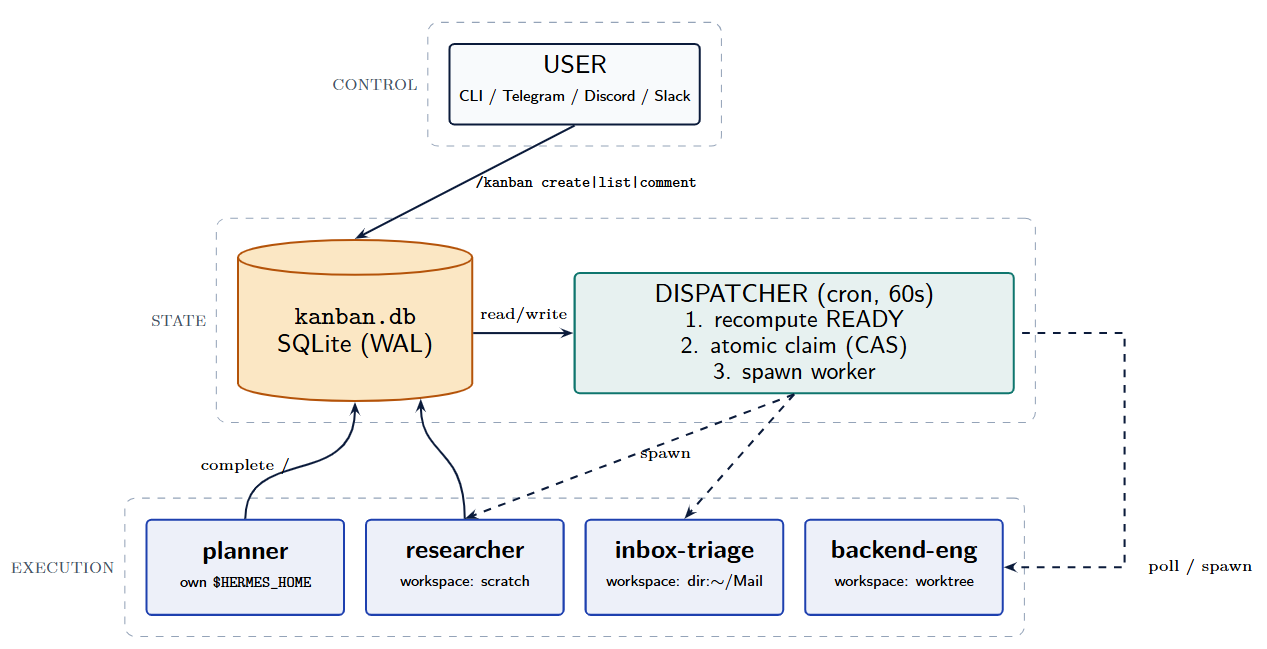

| 层 | 课件名称 | 负责什么 |
| --- | --- | --- |
| 控制层 | Control Plane | CLI、Gateway、Dashboard 接受人类操作 |
| 状态层 | State Plane | SQLite 保存任务；Dispatcher 决定可运行工作 |
| 执行层 | Execution Plane | 启动对应 Profile 的 Worker 进程完成任务 |

课件图中 Dispatcher 标为 cron、60 秒，表示周期扫描这一机制；实际周期按配置，当前默认由 Gateway 内部调度，不是每张卡都安装一条系统 crontab。

协作通过任务板记录状态和交接，避免把“另一个 Agent 已口头说完成”作为唯一依据。图中的 own HERMES_HOME 表示身份状态目录，不保证 Worker 没有权限访问其他文件。


## Board 与 Task：队列分区和具体工作

| 对象 | 核心内容 |
| --- | --- |
| Board | 独立任务队列、数据库、工作目录与相关记录 |
| Task | 标题、目标说明、一个 assignee、状态及运行设置 |
| Link | 上游完成后，下游才有资格继续的依赖关系 |
| Comment | 持久补充要求、发现与交接消息 |
| Event / Run | 状态变更与一次执行的过程记录 |
| Workspace | Worker 具体在哪个目录工作 |

课件默认 Board 数据库位于数据根目录 kanban.db。非默认 Board 位于 kanban/boards/<slug>/，各自保存数据库与工作目录。

~~~text
<HERMES_HOME>/kanban.db
<HERMES_HOME>/kanban/workspaces/<task_id>/
<HERMES_HOME>/kanban/boards/<slug>/
~~~

一个 Task 通常只有一个 assignee，填真实存在的 Profile 名称。多名研究者一起参与同一目标，应创建多张明确任务，再建立依赖或汇总节点，而不是把 assignee 写成一串人名。

Board 分开数据库可以减少队列混淆，但并不自动建立操作系统权限隔离；Worker 实际能访问什么，还要看工具、路径和运行账号。


## 写好 Task body：目标、输入、输出与验收标准

title 便于识别工作，body 才能让 Worker 知道完整要求。只写“研究 Hermes”很难判断范围和完成条件。

下面是 body 的内容示例：

~~~markdown
## 目标
根据给定课程资料和官方文档，说明 Gateway 的消息处理流程。

## 输入
- 已明确的本地资料目录。
- 官方消息平台文档；核对时记录读取日期与适用版本。

## 输出
- gateway-findings.md：流程、关键配置、常见失败点与来源链接。
- 在任务结果中给出文件位置及三项主要结论。

## 约束
- 只读取资料，不接入真实平台，不发送消息。
- 不复制资料中的真实 Token、邮箱密码或私人账号。
- 发现课件与当前接口不同时，分别说明。

## 验收
- 说明准入、路由、Agent 执行、返回平台四个阶段。
- 代码与配置全部放在 Markdown 代码段里。
- 引用来源可定位，未验证的说法标为待确认。
~~~

并行任务依赖的共同格式和已有决定，应写入每张卡的 body。不能假定两个 Worker 自动知道兄弟任务的文件格式、命名规则和最终目标。

明确交付文件路径、内容与验收条件，比只要求“永久保存到桌面”更容易检查。


## Task 状态：等待什么，比列名本身更重要

| 状态 | 本章理解 |
| --- | --- |
| triage | 粗略目标，尚需明确或拆解 |
| todo | 已有任务，但依赖或其他运行条件尚未满足 |
| scheduled | 因时间等原因暂缓，等待相应恢复条件 |
| ready | 可以进入调度认领 |
| running | 已认领，处于执行阶段 |
| blocked | 有具体障碍，需要输入、能力或外部条件 |
| review | 实现结果等待审查 |
| done | 已按任务合同完成并记录结果 |
| archived | 归档，不再参与普通调度 |

基本流程示意：

~~~text
triage → 明确 / 拆解 → todo → 依赖满足 → ready
ready → 原子认领 → running → done
                         ├→ review → done / 返回修改
                         └→ blocked → 补条件 → ready / todo / review
任一符合规则的阶段 → archived
~~~

不同入口、任务设置和版本可能给出不同初始状态，不要用“create 成功”代替检查实际状态。

crashed、timed_out 等通常是执行结果或事件，不宜一概视为固定看板列。需要结合 Task 状态、Run 与 Event 判断它是否等待重试或已经阻塞。


## Link：parent 是上游前置任务，child 是后续任务

依赖方向的含义是：上游先完成，下游才能进入可运行状态。

~~~text
研究 A ─┐
        ├→ 综合报告 → 审阅报告
研究 B ─┘
~~~

对应 CLI 形式：

~~~bash
hermes kanban link RESEARCH_A_ID REPORT_ID
hermes kanban link RESEARCH_B_ID REPORT_ID
hermes kanban link REPORT_ID REVIEW_ID
~~~

所有 ID 要来自实际创建结果或列表。REPORT_ID 等是假名，不是系统已经存在的任务。

| 关系 | 下游的等待条件 |
| --- | --- |
| 一个上游 → 一个下游 | 等待该上游达到可解除依赖的终态 |
| 多个上游 → 一个下游 | 等待所有前置任务满足条件 |
| 一个上游 → 多个下游 | 上游完成后，可以释放多个工作分支 |

课件以 done / archived 作为依赖完成条件。归档会影响调度，不证明上游交付质量合格；下游仍应检查实际交接材料。

“目标拆解树的根节点”与“执行依赖中的 parent”不要混为一谈。必须查看真实依赖图，避免把需要先运行的子工作反而挂到未完成总目标之后。


## 依赖建立时机与常见死锁

运行中的下游已经被认领，再给它添加前置条件，无法当作普通的“先暂停，等上游完成”。当前实现会限制给已经运行的任务直接加依赖，Worker 自身的特定交接路径另有所有权检查。

一个更隐蔽的问题是“给阻塞任务创建帮助卡”：

~~~text
错误方向：阻塞主任务 → 帮助任务
结果：帮助任务等待主任务结束，而主任务正等待帮助任务
~~~

帮助任务的 body 可以引用主任务 ID，描述要补齐的输入，但不应把它依赖到那个尚未完成的主任务。

| 做法 | 结果 |
| --- | --- |
| 所有前置条件在调度前建立 | 下游明确等待所需工作 |
| 帮助卡依赖被帮助的阻塞卡 | 可能形成业务死锁 |
| 把任务间依赖写成一句评论 | 人能读懂，但不会自动形成调度约束 |
| 连错依赖后移除 Link | 可解除错误等待，但还需检查新的运行条件 |

~~~bash
hermes kanban unlink PARENT_ID CHILD_ID
~~~

unlink 会改变依赖，不是完成上游任务，也不是证明缺失输入已经补齐。修改后应查看卡片的依赖和状态。


## Comment：交接要可恢复，不能只留在某个聊天里

课件把 Comment 定义为跨 Agent 交接协议。Worker 启动或重新启动时读取任务评论串，获得补充要求、过去发现和人类决定。

~~~bash
hermes kanban comment TASK_ID "资料按运行日期整理；每项结论保留来源链接，未核对的内容单独列出。"
hermes kanban show TASK_ID
~~~

好的交接记录至少包括：

| 内容 | 示例 |
| --- | --- |
| 已完成部分 | 已读取课程资料并定位配置字段 |
| 证据与产物 | 文件绝对路径、来源链接、验证结果 |
| 尚未完成部分 | 当前文档与课件存在两处差异，等待确认 |
| 下一步所需条件 | 需要选定安装版本后再决定最终命令形式 |

评论保存成功，不代表正在运行的 Worker 已立即收到并采用它。它通常在后续读取或重新运行时进入上下文；需要改变执行状态，还要使用对应管理操作。

任务说明、评论和结果仍是待理解的数据，不应把其中任意外部文本当成凌驾于任务边界的执行指令。


## Event 与 Run：区分“任务状态”和“这次执行发生了什么”

| 记录类型 | 课件事件示例 | 用途 |
| --- | --- | --- |
| 生命周期 | created、promoted、claimed、completed、blocked、unblocked、archived | 查看卡片怎样流转 |
| 人工修改 | assigned、edited、reprioritized、status | 追踪要求、指派与优先级变化 |
| 运行遥测 | spawned、heartbeat、reclaimed、crashed、timed_out、stale、gave_up | 观察 Worker 与恢复过程 |

同一 Task 可以运行多次。第一次因缺少资料阻塞，第二次补齐资料后完成，这两次 Run 应能通过评论、结果与事件区分。

~~~bash
hermes kanban show TASK_ID
hermes kanban tail TASK_ID
hermes kanban watch --kinds completed,blocked
hermes kanban stats
~~~

tail 与 watch 是持续观察入口，不是自动修复命令。读记录时，应把最后一次状态、当前活动 Run 和较早失败分开，不要看到一条历史 crashed 就断言当前还在崩溃。

同样，任务列显示 done 不足以单独证明业务产物正确；应核对 summary、附件与验收证据。


## Workspace：临时目录、已有目录和 Git worktree

| 类型 | 课件写法 | 适用情况 | 要确认什么 |
| --- | --- | --- | --- |
| scratch | 默认或 scratch | 独立研究、短时加工 | 输出是否在清理前保存到持久位置 |
| 现有目录 | dir:<absolute-path> | 长期文档、项目工作目录 | 谁会同时写入这份目录 |
| Git worktree | worktree | 独立代码分支工作 | 仓库、分支、结果合并与保留方式 |

CLI 示例使用 Windows 绝对路径：

~~~bash
hermes kanban create "整理 Gateway 配置字段" \
  --assignee researcher \
  --body "只读明确资料，输出 gateway-findings.md，记录来源与版本；不接入平台。" \
  --workspace dir:C:/hermes-demo/hermes-report
~~~

researcher 必须存在，目录必须已准备好。Linux / WSL 要换成所在环境的绝对路径，而不是把 C: 路径原样传入。

当前文档说明 scratch 会在完成时清理；声明的交付附件可以先复制到持久任务附件存储。课件只强调默认临时目录，因此本篇补充这一点：不要把 scratch 里的路径当作永久交付地址。

worktree 分离工作树，不等于自动合并改动，也不等于给 Agent 创建权限沙箱。并行产物最后仍需要比较、合并和验证。


## Dispatcher：先恢复异常，再推进和认领任务

课件给出四个调度阶段：

1. stale recovery：检查过期认领、进程退出和执行超时。
2. recompute ready：重新判断哪些任务的前置条件已经满足。
3. atomic claim：对符合条件的任务进行原子认领。
4. spawn Worker：启动 assignee 对应的 Profile 工作进程。

~~~yaml
kanban:
  dispatch_in_gateway: true
  dispatch_interval_seconds: 60
~~~

这展示当前默认的 Gateway 内部调度与扫描周期。没有运行中的 Dispatcher 时，ready 可以一直停在那里，并不表示 Worker 已开始。

| 检查对象 | 可能导致无法启动的情况 |
| --- | --- |
| assignee | Profile 不存在、配置不完整 |
| workspace | 路径不存在、仓库不符合所选方式 |
| 依赖 | 有上游未完成 |
| 当前运行记录 | 已被认领、已有 Worker 或处于恢复期 |
| 基础环境 | 模型、凭证、进程启动或服务环境异常 |

当前版本默认在 Gateway 中运行，不应再随意对同一数据库同时开启独立 daemon。多个入口可读同一任务板，与同时保留多个调度循环是两回事。


## 原子认领：把“检查”和“占用”放在一次更新里

课件用比较并交换（CAS）式 SQL 示意认领：

~~~sql
UPDATE tasks
   SET status = 'running',
       claim_lock = ?,
       claim_expires = ?
 WHERE id = ?
   AND status = 'ready'
   AND claim_lock IS NULL;
~~~

问号是数据库参数占位符，分别绑定认领标识、过期时间与任务 ID。这是课件说明并发语义的简化 SQL，不是让学习者直接手工改数据库。

| 更新结果 | 含义 |
| --- | --- |
| 命中 1 行 | 当时仍满足条件，认领成功 |
| 命中 0 行 | 状态、锁或 ID 不再匹配，不能继续按已认领处理 |

如果先查 ready，再无条件更新 running，两个调度者可能都以为自己拿到了同一任务。带条件的一次更新用于关闭这个检查与更新之间的竞态。

原子认领防止同时正常认领，不保证外部写入“恰好一次”。进程写入外部系统后崩溃，再重试时仍可能重复动作；业务需要去重键、结果检查或幂等操作。


## claim 只认领，unblock 只恢复调度资格

课件演示先 claim，再用 unblock“启动 task”。当前 CLI 源码表明，这两步不能当作完整执行入口。

~~~bash
hermes kanban claim TASK_ID
~~~

claim 更新认领状态并解析工作目录，通常会打印 Workspace；它并不在这条命令中启动 Profile Worker。手工认领后如果没有实际执行者，反而可能让任务停在 running 等待恢复。

~~~bash
hermes kanban unblock TASK_ID
~~~

unblock 用于 blocked / scheduled 等符合恢复条件的任务，不是启动任意 running 任务，也不是在原进程里从上次指令继续。

当前文档说明恢复后的状态依上下文决定：依赖未满足回到 todo，已满足的实施任务回 ready，审查阶段可能回 review。不能写成“所有 blocked 都直接回 ready”。

普通自动执行路径是：准备任务与环境 → Dispatcher 认领并启动 Worker → Worker 读取卡片并调用完成或阻塞工具。


## 一条明确的自动执行流程

先确认 Profile 与 Gateway 状态，再创建任务。下面把步骤分开，避免把“卡片创建成功”与“任务已经开始”混为一谈。

~~~bash
hermes profile list
hermes gateway status
hermes kanban init
~~~

假设 researcher 已配置模型、工具和描述，且示例目录存在：

~~~bash
hermes kanban create "梳理 Hermes Gateway 的消息流程" \
  --assignee researcher \
  --body "从指定课程资料与官方消息文档中整理准入、会话路由、Agent执行、回复投递四个阶段。输出 gateway-findings.md，代码与配置使用Markdown代码段，记录来源与版本差异；只读资料，不接入平台。" \
  --workspace dir:C:/hermes-demo/hermes-report
~~~

记录创建结果里的 ID，再观察：

~~~bash
hermes kanban list
hermes kanban show TASK_ID
hermes kanban tail TASK_ID
~~~

| 可见结果 | 下一步确认 |
| --- | --- |
| todo | 还有哪些依赖或运行条件？ |
| ready | Dispatcher 是否在线、能否启动该 Profile？ |
| running | 对应 Worker 与 Run 是否有进展？ |
| blocked | 阻塞理由具体是什么？ |
| done | 产物存在、交接完整、验收是否符合要求？ |

如果 Gateway 未运行，应按已选服务方式启动；本文只展示命令，没有建立真实任务板或工作进程。


## Agent 使用 kanban_* 工具，人类使用 CLI 与看板

两类入口都通过同一任务数据层，但不是同一种调用语法。

| 使用者 | 主要入口 |
| --- | --- |
| 人类 / 自动化脚本 | hermes kanban、/kanban、Dashboard |
| Agent 模型 | kanban_show、kanban_create、kanban_complete、kanban_block 等工具 |

当前模型工具创建汇总任务的示例：

~~~json
{
  "name": "kanban_create",
  "arguments": {
    "title": "综合两份 Gateway 研究结果",
    "assignee": "writer",
    "body": "根据上游交接材料整理中文报告，检查来源日期和版本冲突。输出 report.md，并在结果中给出文件位置与未解决问题；不调用消息发送工具。",
    "parents": ["RESEARCH_A_ID", "RESEARCH_B_ID"],
    "workspace_kind": "dir",
    "workspace_path": "C:/hermes-demo/hermes-report"
  }
}
~~~

writer、目录与上游 ID 都必须是真实对象。CLI 的 --workspace dir:... 对应工具的 workspace_kind / workspace_path，不能直接把 CLI 参数名称放进 JSON。

当前 Worker 工具还受所指派任务和运行所有权约束，不应根据课件的宽泛描述就假定它能自由列出、修改所有兄弟任务。编排者需要的任务板视野，与执行者的当前任务视野不同。


## 完成交接：文件、验证和未解决问题一起记录

Worker 完成后，应把任务结果写回看板，而不只是给聊天发送一句“好了”。

~~~json
{
  "name": "kanban_complete",
  "arguments": {
    "task_id": "TASK_ID",
    "summary": "已整理 Gateway 四阶段流程与配置对照，报告包含来源链接和版本差异；未接入真实平台。",
    "metadata": {
      "changed_files": ["C:/hermes-demo/hermes-report/gateway-findings.md"],
      "verification": "已核对来源，并检查 Markdown 代码段与表格",
      "unresolved": []
    },
    "artifacts": ["C:/hermes-demo/hermes-report/gateway-findings.md"]
  }
}
~~~

这是交接结构示例，不表示该文件已经在本次会话中生成。只有验证确实完成、文件实际存在时，才应该填写相应结果。

| 字段 | 用途 |
| --- | --- |
| summary | 人类与下游能读懂的简短结果 |
| metadata | 验证、决定、文件等结构化事实 |
| artifacts | 真实交付文件的绝对路径 |
| task_id | 正确卡片 ID；非 Worker 入口应明确指定 |

当前版本可以把声明的 scratch 产物复制到持久附件存储，缺失文件则可能拒绝完成并保留当前任务。普通文本中的一个路径，与登记真实产物不能完全等同。

CLI 对应 complete 支持 --summary / --result 等参数；不要手工修改 jobs 或 kanban.db 的状态代替正常完成入口。


## Human-in-the-loop：说明障碍，再补输入和恢复

遇到不能自行解决的前置条件，应记录阻塞原因，而不是虚构完成结果。

~~~json
{
  "name": "kanban_block",
  "arguments": {
    "task_id": "TASK_ID",
    "reason": "资料引用了两个不同版本的接口，缺少当前目标版本；需要明确按课件版本还是实际安装版本整理。"
  }
}
~~~

人类或编排入口补充决定，再恢复：

~~~bash
hermes kanban comment TASK_ID "以实际安装版本为准，同时保留课件写法作为对照。"
hermes kanban unblock TASK_ID
~~~

| 阶段 | 该留下什么 |
| --- | --- |
| Worker 阻塞 | 具体缺什么，已做哪些工作，为什么不能继续 |
| 人类补输入 | 明确决定、有效资料或必要条件 |
| 恢复调度 | 确认依赖与阶段，等待重新派发 |
| Worker 再启动 | 重新读任务、评论与前次结果，检查条件已补齐 |

unblock 不会自动补齐 Token、修复路径或批准业务决策。当前实现还有重复阻塞的防循环行为，持续无条件 unblock 可能把问题送回 triage；应解决原因后再恢复。


## review：等审查，与 blocked 等输入不同

课件列出 review，但主状态图主要展示 done 与 blocked。实际流程中，已经有可审阅结果时可以进入 review，由 reviewer 给出通过或修改意见。

~~~bash
hermes kanban request-review TASK_ID \
  --reviewer reviewer \
  --summary "报告已完成，已核对来源与代码段，请检查结论是否有证据和版本说明。"
~~~

这是当前 CLI 的审查入口。reviewer 必须已存在且配置可运行。

| review | blocked |
| --- | --- |
| 已有结果，等待质量判断 | 缺少输入、能力或外部条件 |
| 审查可能通过或退回修改 | 补齐原因后才恢复执行 |
| 需要交接产物与验证证据 | 需要说明具体障碍 |

当前默认可能自动启动 reviewer，也可以配置为人类审查。是否自动派发、谁负责审查，必须查看实例配置和卡片 assignee。

“已经写完实现”与“整个目标已验收”是两个阶段。审查意见应给出具体问题、位置与期望结果，避免只写“继续优化”。


## 失败恢复：先判断是否还有活跃 Worker

认领过期、进程退出、执行超时和启动失败都需要恢复，但恢复动作不能简单理解为“一律重新跑”。

| 情况 | 要核对的内容 |
| --- | --- |
| Worker 已退出，卡片仍 running | 退出原因、Run、已有产物与外部操作 |
| 认领过期，但进程可能仍活跃 | 进程身份、心跳和进展，避免重复执行 |
| Profile 启动失败 | 凭证、模型、工具与真实 Profile 是否可用 |
| 路径无法准备 | workspace 类型、目录、仓库与权限 |
| 连续重试失败 | 同一个条件是否一直未解决，是否已转 blocked |

课件用 consecutive_failures / max_retries 概括失败门槛；当前版本还使用相应调度失败限制与恢复策略。具体次数按配置和错误类型确认，不能把“可恢复”写成“无限重试”。

恢复前先读 show、事件与日志。已经完成的外部写入、提交、邮件等效果，要核对真实系统；重启 Worker 不能自动撤销它们。

同一业务流程建议明确去重标识和可检查产物。进程恢复解决运行中断，业务幂等解决重复执行，它们是不同问题。


## 六种课件协作模式：选择取决于依赖与状态寿命

| 模式 | 工作形态 | 典型场景 |
| --- | --- | --- |
| Fan-out | 拆成多个独立分支 | 多方向研究、分区实现 |
| Pipeline | 上游完成后下游接手 | researcher → analyst → writer → reviewer |
| Fan-in | 汇聚多个前置结果 | 方案比较、研究综合 |
| Long-running journal | 同一身份在持久目录反复工作 | 日报、周报、长期记录 |
| Human-in-the-loop | 阻塞、补评论、恢复 | 需要人工选择或确认条件 |
| Fleet farming | 同一角色处理多个独立对象 | 多服务巡检、分业务资料整理 |

当前文档的模式数量有所扩展，本篇以课件六类为主。判断方式是：任务能否独立、数据怎样交接、是否需要人工、状态要保存多久。

### Cron 与 Kanban 可以配合

Cron 决定何时产生或运行工作，Kanban 管理任务状态、角色交接和依赖。但创建卡片的自动流程要考虑去重，不能每次重试都产生一批同名工作。

长期日志适合明确的 dir 工作目录；多个角色共享时要规定输出位置和写入顺序，避免把“共享 workspace”理解成谁都可以同时重写同一文件。


## Orchestrator：先发现真实角色，再拆解和汇总

课件把编排分成两个部分：Decomposer 将 triage 目标明确或拆成任务图，Orchestrator 负责路由、交接和判断总目标是否完成。

| 编排者应负责 | Worker 应负责 |
| --- | --- |
| 确认目标与统一格式 | 完成所分配的具体研究或实现 |
| 查实际 Profile 与职责描述 | 读取自己的完整任务说明 |
| 创建任务、依赖、验收条件 | 保存发现、验证和交付文件 |
| 综合结果、处理失败与冲突 | 明确完成或具体阻塞理由 |

创建编排 Profile 的课件示例：

~~~bash
hermes profile create orchestrator --clone \
  --description "拆解高层目标，创建任务，指派真实存在的Profile，建立依赖，汇总结果；不直接执行研究、写作、编码或运维工作。"
~~~

然后在拥有任务板配置的 Profile 中设置编排目标：

~~~yaml
kanban:
  orchestrator_profile: orchestrator
  auto_decompose: true
~~~

auto_decompose 可能调用辅助模型，不是纯本地拆字符串。课件建议加载 kanban-orchestrator Skill；当前文档说明 Worker / 编排指导已有自动注入路径，不能假定所有当前安装都必须另装同名 Skill。

description 帮助路由，不会创建缺失角色。为不存在的 reviewer 指派任务，不能靠模型“理解这个角色”就启动成功。


## 限制编排者的执行能力，还要确认实际平台工具列表

课件通过关闭执行型工具，减少编排者直接代替 Worker 工作的情况。当前 tools disable 支持多个工具集名称，以及 --platform 作用域。

~~~bash
hermes -p orchestrator tools disable terminal file web browser code_execution --platform cli
hermes -p orchestrator tools enable kanban memory --platform cli
hermes -p orchestrator tools list --platform cli
~~~

禁用几类工具，不自动等于“只剩 kanban 与 memory”。还应检查当前启用的组合工具集、MCP、插件与其他入口；Gateway 平台也可能有独立工具配置。

任务说明中的“不直接执行”是行为约束，工具限制是可用能力约束，两者一起使用更容易保持角色清楚。需要通知能力时，应明确添加相应入口及任务授权，不能为了编排便利默认放开所有消息发送。

编排前先决定跨任务共同使用的格式、命名、数据版本与接口。两个并行 Worker 各自发明不同文件格式，会把协调成本留给后续汇总。


## Swarm：一次创建并行研究、核验与综合的图

课件的 swarm 入口把多个 Worker、一个 verifier 和一个 synthesizer 组织成任务图：

~~~text
多个 Worker 并行 → verifier 核验 → synthesizer 综合
~~~

~~~bash
hermes kanban swarm "研究 Hermes 架构，整理带来源链接与版本差异的中文报告；只读公开和已指定资料，不接入平台" \
  --worker "researcher:Agent Loop 分析" \
  --worker "researcher:Skills 系统分析" \
  --worker "researcher:Gateway 架构分析" \
  --verifier reviewer \
  --synthesizer writer
~~~

researcher、reviewer、writer 都要先创建并配置，创建后查看实际任务图和每张卡的 body。不能把 --worker 的文字当成自动生成 Profile 的命令。

课件把所有角色都指定为 default，适合说明参数形式，但不代表形成了不同专长或独立持久身份。本例用具名角色展示路由，是否并行派发还取决于配置、容量与实际运行条件。

swarm 创建工作图与启动 Worker 是两个阶段；创建成功后还要确认 Dispatcher 状态、依赖和交付位置。


## Tenant 与多 Board：业务标签和队列分区

Tenant 是 Task 上的可选命名空间。同一个 researcher 可以服务多个业务，但每个任务要带清楚的标签、资料范围与目录。

~~~bash
hermes kanban create "整理 business-a 月报资料" \
  --assignee researcher \
  --tenant business-a \
  --body "只处理指定业务目录，结果写入本目录，交接中保留数据月份与来源。" \
  --workspace dir:C:/hermes-demo/tenants/business-a/data
hermes kanban list --tenant business-a
~~~

| 分区方式 | 主要作用 |
| --- | --- |
| Tenant | 过滤、审计、业务标签与约定 |
| Workspace 路径 | 明确本次操作目录与文件范围 |
| 不同 Profile | 分开 Hermes 身份状态 |
| 不同 Board | 分开任务队列、依赖与相关记录 |
| OS / 容器权限 | 控制真实资源访问范围 |

课件明确 Tenant 是软隔离，不是安全边界。tenant 不会自动让 MEMORY.md 按业务拆成不同文件，长期记忆需要另外设计命名或后端隔离。

建立与选择 Board 的入口：

~~~bash
hermes kanban boards list
hermes kanban boards create course-report --name "课程资料整理"
hermes kanban boards switch course-report
hermes kanban --board course-report list
~~~

switch 设置后续操作的活动任务板，已有卡片不会自动搬家。明确 --board 有助于避免在多个项目间操作错对象。


## 常用管理入口：把查询、调度和删除分清

| 目标 | 主要命令形式 |
| --- | --- |
| 初始化与查询 | init、list、show、stats |
| 指派与修改 | assign、edit、comment |
| 建立或解除依赖 | link、unlink |
| 结束或暂停工作 | complete、block、archive |
| 恢复运行条件 | unblock，其他恢复命令按版本使用 |
| 观察进展 | watch、tail |
| 一次调度 | dispatch，可用 --dry-run / --max |
| 明确与拆解粗略目标 | specify、decompose |
| 一次创建协作图 | swarm |
| 工作队列分区 | boards list / create / switch / rm |
| 临时目录清理 | gc，范围按当前帮助确认 |

~~~bash
hermes kanban dispatch --dry-run
hermes kanban specify TASK_ID
hermes kanban decompose TASK_ID
~~~

dispatch --dry-run 的含义重点是预览调度、避免真正派发 Worker，不应把所有版本的 dry-run 都当作完全无状态变化。specify / decompose 会按配置调用模型并修改任务规格或图。

以下是归档与删除的不同入口示例，阅读时需要区分对象：

~~~bash
hermes kanban archive TASK_ID
hermes kanban boards rm course-report
hermes kanban boards rm course-report --delete
hermes profile delete coder
~~~

archive 是归档卡片；boards rm 默认归档整个 Board，--delete 是硬删除；profile delete 则删除身份及其数据，不是只从看板移除一个 assignee。它们不应该放进普通执行流程里自动连续运行。

本文没有执行这些管理操作。课件把 gc 概括为清理归档 scratch，当前版本的维护范围可能扩大，使用前先看对应帮助和预览能力。


## 排查协作问题：先看入口，再看身份和任务状态

| 现象 | 先核对什么 |
| --- | --- |
| Bot 不回复 | Gateway 连接、模型、准入策略、会话路由、平台群聊限制 |
| 配对后命令仍被拒绝 | 平台与 Profile、私信 / 群聊作用域、admin 分层 |
| 克隆 Profile 后 Bot 没接通 | 当前克隆默认不带消息身份，需要单独配置 |
| 两个身份消息连接互相失效 | Bot 凭证重复、独立与 multiplex 进程冲突 |
| 子 Agent 不理解任务 | context 是否含路径、错误、约束和验收 |
| 委派调用报未知字段 | 当前 Schema 是否还接受 toolsets / role / 顶层 goal |
| 子任务返回但父任务无法推进 | 状态、字段验证、证据与未完成工作 |
| 卡片长期 ready | Dispatcher 在线、Profile 存在、环境与路径可用 |
| 手工 claim 后停在 running | 是否真的启动了执行者、认领是否仍有效 |
| 卡片长期 todo | 上游状态、Link 方向、是否形成帮助卡死锁 |
| unblock 后又 blocked | 障碍有没有被实际解决，是否进入防循环流程 |
| 完成后文件找不到 | 是否在 scratch，是否声明或保存持久交付文件 |
| 不同业务内容混在一起 | Tenant、目录、Profile 记忆与外部后端是否分别设计 |

不要同时改 Token、默认 Profile、Board 与工作目录来碰运气。一次确定一层的实际对象，才能知道问题是连接、路由、权限、任务合同还是执行恢复。


## 课件与当前接口的差异速查

| 课件写法或结论 | 本篇的说明 |
| --- | --- |
| CLI 是单次交互入口 | CLI 也可以持续对话，区别在入口与运行形态 |
| 普通 gateway install 是系统服务 | Linux 普通入口是用户服务，--system 才是系统作用域 |
| 微信、邮件示例允许所有用户 | 改用明确名单和占位凭证，并说明平台实际策略 |
| Profile clone-all 复制完整状态 | 当前排除历史与 Cron 等，不等于完整备份 |
| 每个 Profile 都独立启动 Gateway | 当前还支持 multiplex，先确认实际服务架构 |
| delegate_task 顶层 goal / context、toolsets | 当前示例用 tasks 数组，工具从父 Agent 继承 |
| 默认委派并发数 3 | 当前默认 10；示例显式设 3 为策略 |
| role 参数控制是否再次委派 | 当前 main 根据开关与深度确定能力，role 为旧兼容字段 |
| code_execution 对子 Agent 不可用 | 当前保留 execute_code |
| 子任务详细对话不保留 | 不直接进入父上下文，但当前可以有数据库与转录记录 |
| claim 后再 unblock 就能启动 | claim 只认领；自动启动来自 Dispatcher，unblock 只恢复相应资格 |
| blocked 一律恢复 ready | 当前还会回 todo 或 review，取决于依赖与来源阶段 |
| scratch 只需关注创建临时目录 | 当前完成时会清理，交付需登记或持久保存 |
| 必须额外加载 kanban-orchestrator Skill | 当前指导存在自动注入路径，按安装版本确认 |

公开 main 和在线文档仍会更新，甚至存在文档与源码描述不同步。本篇优先核对模型 Schema 和具体命令实现，并保留课件机制的解释；未对用户安装实例运行这些功能。


## 本章复习：谁接收、谁保存、谁执行、怎样交接？

| 模块 | 需要记住的核心 |
| --- | --- |
| Gateway | 接通消息、检查访问、路由会话、返回结果 |
| Profile | 保存长期身份状态，不能自动代替沙箱 |
| Delegation | 给独立子任务完整背景，读取结果状态与证据 |
| Kanban | 保存任务合同、依赖、评论、运行和产物 |
| Dispatcher | 判断运行条件、原子认领并启动 Worker |
| Orchestrator | 决定共同约定、拆解、路由、综合与验收 |
| Worker | 完成具体工作，诚实交回结果或阻塞原因 |

复习题：

1. Telegram Token、用户 ID 和配对码分别解决什么问题？
2. 普通用户只能使用 /status，为什么不代表普通聊天完全不能触发工具？
3. HERMES_HOME 与 terminal.cwd 有什么区别？
4. 为什么“修复刚才的错误”不是好的子 Agent context？
5. 两个研究任务汇总到一份报告，Link 应按哪个方向建立？
6. claim 成功后为什么还不能认定任务已经开始执行？
7. 帮助卡为什么不能依赖它要帮助的阻塞主任务？
8. 交付文件在 scratch 中时，怎样避免完成后找不到？

本章的重点是让协作有明确对象与可读记录。运行更多 Agent 之前，先把目标、上下文、依赖、产物和完成标准写清楚。


## 来源与延伸阅读

主要来源是 [本地课程课件压缩包](D:/baidudisk/BaiduNetdiskDownload/1、课件(1)/1.课件.rar) 中的《04-协作篇.md》，架构图来自同包 images/hermes_kanban_architecture.png。

本地文件目录列了“高级特性集锦”，但实际正文在 Kanban swarm 示例后结束，没有独立的第 5 节。本篇按已提供的正文整理，结构化委派结果、Windows 服务方式等补充均标明来自当前官方资料。

| 内容 | 官方资料 |
| --- | --- |
| Gateway、配对、访问和服务运行 | [Messaging Platforms](https://hermes-agent.nousresearch.com/docs/user-guide/messaging/) |
| Telegram | [Telegram](https://hermes-agent.nousresearch.com/docs/user-guide/messaging/telegram/) |
| 微信 iLink | [Weixin](https://hermes-agent.nousresearch.com/docs/user-guide/messaging/weixin/) |
| Email 接入 | [Email](https://hermes-agent.nousresearch.com/docs/user-guide/messaging/email/) |
| 身份、克隆与工作目录 | [Profiles](https://hermes-agent.nousresearch.com/docs/user-guide/profiles/) |
| 委派、上下文、工具与深度 | [Subagent Delegation](https://hermes-agent.nousresearch.com/docs/user-guide/features/delegation/) |
| 任务板、依赖、交接与调度 | [Kanban](https://hermes-agent.nousresearch.com/docs/user-guide/features/kanban/) |

接口核对主要使用公开 main 的 [delegate_tool.py](https://github.com/NousResearch/hermes-agent/blob/main/tools/delegate_tool.py)、[子 Agent 工具权限](https://github.com/NousResearch/hermes-agent/blob/main/tools/delegate_tool_toolsets.py)、[Kanban Schema](https://github.com/NousResearch/hermes-agent/blob/main/tools/kanban_tools_schemas.py)、[Kanban CLI](https://github.com/NousResearch/hermes-agent/blob/main/hermes_cli/kanban.py)、[Kanban 命令解析器](https://github.com/NousResearch/hermes-agent/blob/main/hermes_cli/kanban_parser.py)、[Profiles 实现](https://github.com/NousResearch/hermes-agent/blob/main/hermes_cli/profiles.py)、[Gateway 命令解析器](https://github.com/NousResearch/hermes-agent/blob/main/hermes_cli/subcommands/gateway.py)。读取日期：2026-10-09。

示例已经过静态结构、参数与 Markdown 渲染检查，没有执行真实课程功能。
